# Chronic kidney disease (CKD) risk model

Source: UCI Chronic Kidney Disease (id 336). 400 patients from a hospital in Karaikudi, Tamil Nadu.
MedTrail uses 8 inputs that lab reports and the patient profile can provide:

| Column | Meaning | MedTrail test name |
|---|---|---|
| sc | Serum creatinine (mg/dL) | Serum Creatinine |
| bu | Blood urea (mg/dL) | Blood Urea |
| hemo | Haemoglobin (g/dL) | Hemoglobin |
| al | Urine albumin (dipstick 0-5) | Urine Albumin |
| su | Urine sugar (dipstick 0-5) | Urine Sugar |
| bgr | Random blood glucose (mg/dL) | Glucose |
| bp | Blood pressure (mm Hg) | from patient profile |
| age | Age (years) | from patient profile |
| **class** | **Target: ckd / notckd** | |

In [1]:
import sys
from pathlib import Path

import joblib
import pandas as pd
from sklearn.metrics import roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT))   # lets the notebook import our own code from src/

from src.prediction.train_utils import (compare_models, make_models, risk_level, risk_level_table,
                                        save_model, split_data, test_best_model)
print("Project folder:", ROOT)

Project folder: c:\Users\Amupam Raj\projects\medtrail-ai


In [2]:
df = pd.read_csv(ROOT / "datasets" / "raw" / "kidney" / "ckd.csv")
print(df.shape)

FEATURES = ["sc", "bu", "hemo", "al", "su", "bgr", "bp", "age"]
for col in FEATURES:
    # remove stray spaces/tabs, then make the column numeric (anything unreadable becomes missing)
    df[col] = pd.to_numeric(df[col].astype(str).str.strip(), errors="coerce")

df["class"] = df["class"].str.strip()          # fixes the 'ckd\t' typo
df["target"] = (df["class"] == "ckd").astype(int)

print(df["class"].value_counts())
print(f"CKD rate: {df['target'].mean():.1%}")
print(f"Accuracy if we always guess 'CKD': {df['target'].mean():.1%}")

(400, 25)
class
ckd       250
notckd    150
Name: count, dtype: int64
CKD rate: 62.5%
Accuracy if we always guess 'CKD': 62.5%


In [3]:
missing = df[FEATURES].isna().sum()
print(pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(1)}))

print("\nMedian value (0 = no CKD, 1 = CKD):")
print(df.groupby("target")[FEATURES].median().round(2))

# ROC-AUC of each input used ALONE (0.5 = useless, 1.0 = perfect separation)
single = {}
for col in FEATURES:
    known = df[col].notna()
    auc = roc_auc_score(df.loc[known, "target"], df.loc[known, col])
    single[col] = max(auc, 1 - auc)   # some inputs go DOWN with CKD (e.g. haemoglobin)
print("\nHow well each input separates CKD on its own:")
print(pd.Series(single).round(3).sort_values(ascending=False))

      missing  percent
sc         17      4.2
bu         19      4.8
hemo       52     13.0
al         46     11.5
su         49     12.2
bgr        44     11.0
bp         12      3.0
age         9      2.2

Median value (0 = no CKD, 1 = CKD):
          sc    bu  hemo   al   su    bgr    bp   age
target                                               
0       0.90  33.0  15.0  0.0  0.0  107.5  70.0  46.0
1       2.25  53.0  10.9  2.0  0.0  143.5  80.0  59.0

How well each input separates CKD on its own:
hemo    0.969
sc      0.923
al      0.871
bu      0.751
bgr     0.747
bp      0.666
age     0.665
su      0.648
dtype: float64


In [4]:
X = df[FEATURES]
y = df["target"]
X_train, X_test, y_train, y_test = split_data(X, y)
print("Training patients:", len(X_train), "| Test patients:", len(X_test))

models = make_models()
cv_results = compare_models(models, X_train, y_train)
cv_results

Training patients: 320 | Test patients: 80


,roc_auc,accuracy,precision,recall,f1,roc_auc_spread
model,,,,,,
Random Forest,0.998,0.966,0.975,0.970,0.972,0.001
XGBoost,0.996,0.975,0.975,0.985,0.980,0.003
Logistic Regression,0.995,0.956,0.975,0.955,0.965,0.005


Best model (highest cross-validated ROC-AUC): Random Forest
Results on the 80 test patients (used only once):
  roc_auc   0.998
  accuracy  0.950
  precision 0.979
  recall    0.940
  f1        0.959


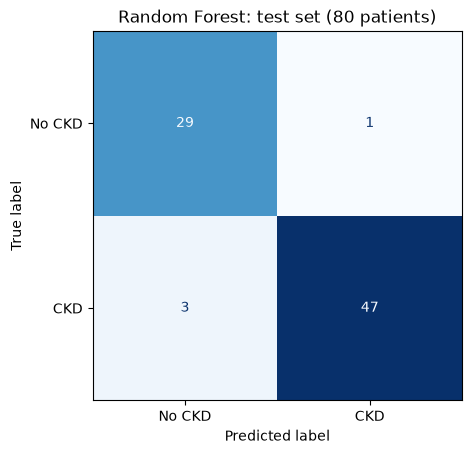

In [5]:
best_name, best_model, proba, test_metrics = test_best_model(
    cv_results, models, X_train, y_train, X_test, y_test, labels=["No CKD", "CKD"]
)

In [6]:
risk_level_table(proba, y_test)

,patients,actually_had_disease
risk_level,,
Low,29,0%
Moderate,3,100%
High,48,98%


In [7]:
save_model(ROOT / "models", "kidney", best_name, best_model, FEATURES, cv_results, test_metrics, notes={
    "dataset": "UCI Chronic Kidney Disease (id 336), 400 patients, Karaikudi, Tamil Nadu",
    "target": "1 = ckd, 0 = notckd (the 'ckd\\t' typo was cleaned)",
    "feature_meaning": {
        "sc": "Serum Creatinine (mg/dL)", "bu": "Blood Urea (mg/dL)", "hemo": "Hemoglobin (g/dL)",
        "al": "Urine Albumin (dipstick 0-5)", "su": "Urine Sugar (dipstick 0-5)",
        "bgr": "Random blood glucose (mg/dL)", "bp": "Blood pressure (mm Hg)", "age": "Age (years)",
    },
    "limitation": "Small single-hospital dataset where haemoglobin alone almost separates the groups, "
                  "so near-perfect scores reflect an easy dataset, not proven clinical accuracy.",
})

Saved: kidney_pipeline.joblib and kidney_metrics.json


In [8]:
loaded = joblib.load(ROOT / "models" / "kidney_pipeline.joblib")
samples = pd.DataFrame([
    {"sc": 3.2, "bu": 80, "hemo": 9.5, "al": 3, "su": 0, "bgr": 140, "bp": 90, "age": 60},
    {"sc": 0.9, "bu": 30, "hemo": 14.5, "al": 0, "su": 0, "bgr": 100, "bp": 70, "age": 40},
])
names = ["Patient with kidney-damage signs", "Patient with normal values"]
for name, p in zip(names, loaded.predict_proba(samples)[:, 1]):
    print(f"{name}: probability {p:.2f} -> {risk_level(p)} risk")

Patient with kidney-damage signs: probability 1.00 -> High risk
Patient with normal values: probability 0.02 -> Low risk
